# Uneven Ground: exploring the Trans Rights Indicator Project

This notebook is the analysis behind *Uneven Ground*, a scrollytelling article
about trans legal rights in 173 countries between 2000 and 2021. The data is
Myles Williamson's Trans Rights Indicator Project (TRIP), published in
*Perspectives on Politics*, Vol. 22, No. 3 (2024).

I used it to get to know the dataset before designing anything, to test each
claim I wanted to make, and to decide which charts were worth building. Most of
what I tried here did not make it into the article. I kept those threads and
noted why I dropped them.

1. Loading the data
2. Getting to know the dataset
3. Checking how the score is built
4. What the score moves with
5. Who moved the most
6. Does the average tell the truth?
7. The shape of the distribution
8. Regions
9. The thirteen indicators
10. Going backwards
11. Recognition versus protection, and choosing the country cards
12. Colonial law and the LGB comparison
13. Every country, every year
14. Choosing the map's zoom stops
15. From notebook to article

Every number quoted in the article is recomputed in the fact sheet at the end.

## 1. Loading the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, BoundaryNorm
import seaborn as sns
from sklearn.cluster import KMeans

%matplotlib inline
pd.set_option("display.max_rows", 40)
pd.set_option("display.width", 120)

# Same colours as the article, so the sketches here look like the final charts.
PAPER, RULE, TEXT, GREY = "#F7F5F0", "#D6D2C8", "#111111", "#67655F"
PRIMARY, PRIMARY_LIGHT, ACCENT = "#5A37D1", "#AEACF9", "#FF4E00"

# Score classes used by the map and the heatmap (section 13 explains the bins).
CLASSES = [(0, 0, "0", "#E2C157"), (1, 1, "1", "#42B59A"), (2, 2, "2", "#008FB5"),
           (3, 4, "3-4", "#295DC4"), (5, 8, "5-8", "#521CA9"), (9, 13, "9-13", "#490053")]
class_cmap = ListedColormap([c[3] for c in CLASSES])
class_norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 4.5, 8.5, 13.5], class_cmap.N)
seq_cmap = LinearSegmentedColormap.from_list("seq", [c[3] for c in CLASSES])
div_cmap = LinearSegmentedColormap.from_list("div", [ACCENT, PAPER, PRIMARY])

plt.rcParams.update({
    "figure.facecolor": PAPER, "axes.facecolor": PAPER, "savefig.facecolor": PAPER,
    "axes.edgecolor": GREY, "axes.labelcolor": TEXT, "text.color": TEXT,
    "xtick.color": GREY, "ytick.color": GREY, "grid.color": RULE,
    "axes.grid": True, "grid.linewidth": 0.5, "font.size": 10, "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
})

df = pd.read_csv("../src/data/raw/trans_rights_worldwide.csv")
df["year"] = df["year"].astype(int)
data = df[df["year"].between(2000, 2021)].copy()          # the article's window
scored = data.dropna(subset=["trip_score"]).copy()         # country-years with a score
names = scored.drop_duplicates("country_text_id").set_index("country_text_id")["country_name"]

print(f"Raw file: {len(df):,} rows, {df.shape[1]} columns, {df['year'].min()}-{df['year'].max()}")
print(f"2000-2021: {len(data):,} rows, {len(scored):,} with a TRIP score, {scored['country_text_id'].nunique()} countries")

Raw file: 3,967 rows, 51 columns, 1999-2021
2000-2021: 3,795 rows, 3,781 with a TRIP score, 173 countries


## 2. Getting to know the dataset

Before trusting anything, I checked what the file contains, how many countries
each year has, and which columns are mostly empty.

In [2]:
missing = data.isna().mean().mul(100).round(1).sort_values(ascending=False)
print("Columns with missing values (% of rows):")
print(missing[missing > 0].to_string())

Columns with missing values (% of rows):
lgb_marriage                95.4
lgb_legal                   95.4
lgb_const                   95.4
lgb_secondparentadoption    95.4
lgb_score                   95.4
lgb_percent                 95.4
lgb_hatecrime               95.4
lgb_broad                   95.4
lgb_employ                  95.4
lgb_unions                  95.4
lgb_jointadoption           95.4
lgb_banconv                 95.4
lgb_incitement              95.4
nrepc_rcs                   28.2
muspc_rcs                   27.9
chrpc_rcs                   27.4
relpc_rcs                   27.4
e_polity2                   18.8
e_boix_regime                5.7
lgdppc_wb                    2.0
wb_gdppc                     2.0
gmcdiv                       0.9
no_indcrim                   0.9
nopsych                      0.9
nophys                       0.9
nodiv                        0.9
gmcphys                      0.9
gmcpsych                     0.9
gmc                          0.9
gm

Countries without a score in 2000: {'Kosovo': 2008, 'Montenegro': 2006, 'South Sudan': 2011}


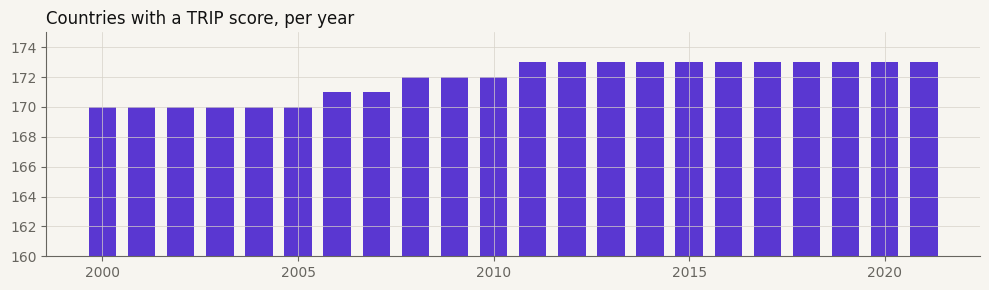

In [3]:
coverage = scored.groupby("year")["country_text_id"].nunique()
first_year = scored.groupby("country_name")["year"].min()
print("Countries without a score in 2000:", first_year[first_year > 2000].to_dict())

fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(coverage.index, coverage.values, color=PRIMARY, width=0.7)
ax.set_ylim(160, 175)
ax.set_title("Countries with a TRIP score, per year", loc="left")
fig.tight_layout()

Coverage is close to complete: 170 countries in 2000 and 173 in 2021. The
three late entries are Kosovo, Montenegro and South Sudan, which became
independent during the period.

The `lgb_*` columns (an LGB rights score from ILGA) are almost entirely empty.
They only exist for 2020, so any comparison with LGB rights is a single-year
snapshot, not a trend.

## 3. Checking how the score is built

My first chart of indicator adoption showed some indicators above 100% of
countries, which is impossible. I had averaged the raw columns, and that only
works if every column means "1 = the right is in law". It doesn't:

- `dir_crim` and `ind_crim` are 1 when trans people **are** criminalized.
- `gmcphys`, `gmcpsych` and `gmcdiv` are 1 when a requirement (surgery, a
  psychiatric diagnosis, divorce) **exists**, and 2 when there is no legal
  gender change to attach it to.
- The rest are 1 when the right is held.

The file also has a `gmcpr` column (a procedure requirement) and an
`adp_general` column. To find out which of them belong in the score, I rebuilt
`trip_score` from the indicators, with the value that means "held" for each.

In [4]:
INDICATORS = [
    # column,            held, label,                                 group
    ("dir_crim",          0,   "No direct criminalization",           "Criminalization"),
    ("ind_crim",          0,   "No indirect criminalization",         "Criminalization"),
    ("gmc",               1,   "Legal gender marker change",          "Recognition"),
    ("gmcphys",           0,   "No surgery or physical requirement",  "Recognition"),
    ("gmcpsych",          0,   "No psychiatric diagnosis required",   "Recognition"),
    ("gmcdiv",            0,   "No divorce requirement",              "Recognition"),
    ("nb3g",              1,   "Nonbinary or third gender marker",    "Recognition"),
    ("adp_general",       1,   "General anti-discrimination law",     "Protection"),
    ("adp_employment",    1,   "Protection in employment",            "Protection"),
    ("adp_education",     1,   "Protection in education",             "Protection"),
    ("adp_healthcare",    1,   "Protection in healthcare",            "Protection"),
    ("adp_housing",       1,   "Protection in housing",               "Protection"),
    ("adp_constitution",  1,   "Constitutional protection",           "Protection"),
]
HELD = {col: held for col, held, *_ in INDICATORS}
LABEL = {col: label for col, _, label, _ in INDICATORS}

def holds(frame, col):
    return frame[col] == HELD[col]

rebuilt = sum(holds(scored, c).astype(int) for c in HELD)
print(f"Rebuilt score equals trip_score in {(rebuilt == scored['trip_score']).mean():.1%} of {len(scored):,} country-years")

print("\nHow the requirement columns are coded in 2021:")
scored[scored.year == 2021][["dir_crim", "gmc", "gmcphys", "gmcpsych", "gmcdiv"]].apply(
    lambda s: s.value_counts(dropna=False)).fillna(0).astype(int)

Rebuilt score equals trip_score in 100.0% of 3,781 country-years

How the requirement columns are coded in 2021:


,dir_crim,gmc,gmcphys,gmcpsych,gmcdiv
0.0,161,112,26,19,26
1.0,12,60,25,28,23
2.0,0,0,121,125,123
NaN,0,1,1,1,1


A perfect match: the score is these 13 indicators, `adp_general` included and
`gmcpr` left out. From here on every share is computed with the right "held"
value, and only among countries that have data that year.

## 4. What the score moves with

A quick correlation pass across every numeric column, mostly as a sanity check.

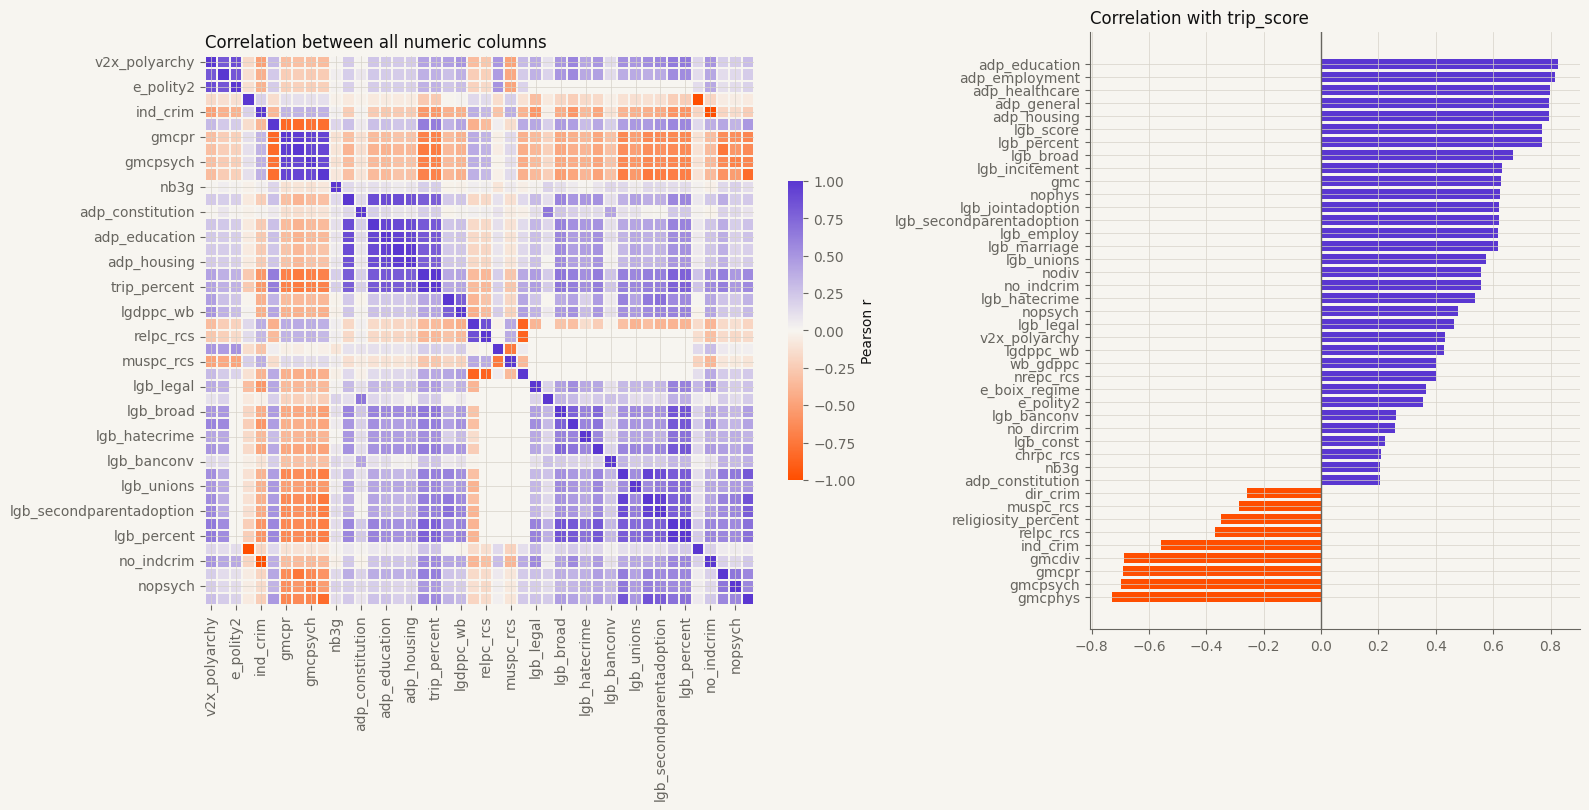

In [5]:
numeric = [c for c in data.columns if pd.api.types.is_numeric_dtype(data[c]) and c not in ("country_id", "year")]
corr = data[numeric].corr()
trip_corr = corr["trip_score"].drop(["trip_score", "trip_percent"]).dropna().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 8), gridspec_kw={"width_ratios": [1.4, 1]})
sns.heatmap(corr, cmap=div_cmap, center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.3, linecolor=PAPER, cbar_kws={"shrink": 0.5, "label": "Pearson r"}, ax=axes[0])
axes[0].set_title("Correlation between all numeric columns", loc="left")
axes[1].barh(trip_corr.index, trip_corr.values, color=[PRIMARY if v > 0 else ACCENT for v in trip_corr])
axes[1].axvline(0, color=GREY, lw=1)
axes[1].set_title("Correlation with trip_score", loc="left")
fig.tight_layout()

The protection indicators correlate most strongly with the total, followed by
the LGB score. Nothing surprising, and nothing I wanted to chart: a
correlation ranking answers "what predicts the score", and the story I was
after is about how the scores spread apart over time.

## 5. Who moved the most

Argentina: {'score_2000': 1.0, 'score_2021': 6.0, 'change': 5.0} | rank by gain: 20
Lost ground: ['The Gambia', 'Equatorial Guinea', 'Indonesia', 'Cambodia', 'Kuwait', 'Oman']


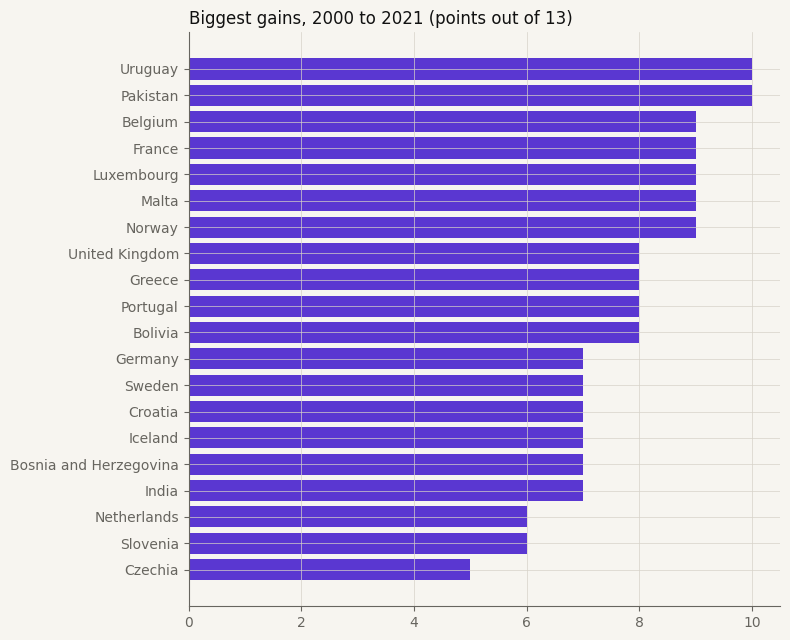

In [6]:
scores = scored.pivot_table(index="country_text_id", columns="year", values="trip_score", aggfunc="first")
change = (scores[[2000, 2021]].dropna()
          .rename(columns={2000: "score_2000", 2021: "score_2021"})
          .assign(change=lambda t: t.score_2021 - t.score_2000, country=lambda t: names[t.index]))

top = change.sort_values(["change", "score_2021"], ascending=False).head(20)
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(top.country[::-1], top.change[::-1], color=PRIMARY)
ax.set_title("Biggest gains, 2000 to 2021 (points out of 13)", loc="left")
fig.tight_layout()

print("Argentina:", change.loc["ARG", ["score_2000", "score_2021", "change"]].to_dict(),
      "| rank by gain:", int((change.change > change.loc["ARG", "change"]).sum()) + 1)
print("Lost ground:", change[change.change < 0].country.tolist())

Pakistan and Uruguay gained the most, ten points each, followed mostly by
Western European countries, Bolivia and India. Argentina, which I expected to
see near the top because of its 2012 law, gained five points and only ties
for 20th place.

Six countries ended lower than they started. I come back to them in section 10.

A ranking like this is a good sidebar, but it flattens the distribution, which
turned out to be the whole story. It did give me a first list of countries to
look at more closely.

## 6. Does the average tell the truth?

The headline number is easy to find: the average score more than doubled. I
wanted to know whether the typical country actually moved, so I looked at the
whole distribution, year by year.

In [7]:
by_year = scored.groupby("year")["trip_percent"]
dist = pd.DataFrame({
    "countries": by_year.size(),
    "p10": by_year.quantile(.10), "p25": by_year.quantile(.25), "median": by_year.median(),
    "mean": by_year.mean(), "p75": by_year.quantile(.75), "p90": by_year.quantile(.90),
})
dist.loc[[2000, 2005, 2010, 2015, 2021]].style.format({c: "{:.1%}" for c in dist.columns if c != "countries"})

,countries,p10,p25,median,mean,p75,p90
year,,,,,,,
2000,170,7.7%,7.7%,7.7%,10.9%,15.4%,15.4%
2005,170,7.7%,7.7%,7.7%,11.8%,15.4%,23.1%
2010,172,7.7%,7.7%,7.7%,14.8%,15.4%,30.0%
2015,173,7.7%,7.7%,15.4%,18.5%,23.1%,46.2%
2021,173,7.7%,7.7%,15.4%,23.5%,30.8%,61.5%


Average:  10.9% -> 23.5%
Median:   7.7% -> 15.4% (first year at the higher value: 2015)
25th pct: 7.7% -> 7.7%
90th pct: 15.4% -> 61.5%
Average minus median: 3.2 pts in 2000, 8.1 pts in 2021
Interquartile range: 7.7 pts in 2000, 23.1 pts in 2021
10th percentile equals the 25th in every year: True


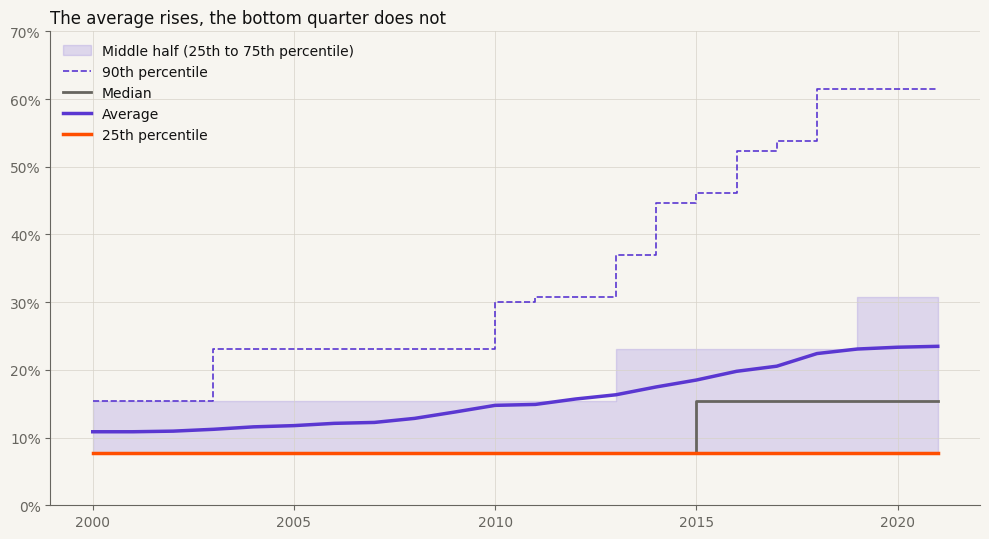

In [8]:
fig, ax = plt.subplots(figsize=(10, 5.5))
yrs = dist.index
ax.fill_between(yrs, dist.p25, dist.p75, step="post", color=PRIMARY, alpha=0.16, label="Middle half (25th to 75th percentile)")
ax.step(yrs, dist.p90, where="post", color=PRIMARY, lw=1.2, ls="--", label="90th percentile")
ax.step(yrs, dist["median"], where="post", color=GREY, lw=2, label="Median")
ax.plot(yrs, dist["mean"], color=PRIMARY, lw=2.5, label="Average")
ax.step(yrs, dist.p25, where="post", color=ACCENT, lw=2.5, label="25th percentile")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_ylim(0, 0.7)
ax.set_title("The average rises, the bottom quarter does not", loc="left")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()

print(f"Average:  {dist['mean'][2000]:.1%} -> {dist['mean'][2021]:.1%}")
print(f"Median:   {dist['median'][2000]:.1%} -> {dist['median'][2021]:.1%} (first year at the higher value: {dist[dist['median'] > dist['median'][2000]].index.min()})")
print(f"25th pct: {dist.p25[2000]:.1%} -> {dist.p25[2021]:.1%}")
print(f"90th pct: {dist.p90[2000]:.1%} -> {dist.p90[2021]:.1%}")
print(f"Average minus median: {(dist['mean'] - dist['median'])[2000]*100:.1f} pts in 2000, {(dist['mean'] - dist['median'])[2021]*100:.1f} pts in 2021")
print(f"Interquartile range: {(dist.p75 - dist.p25)[2000]*100:.1f} pts in 2000, {(dist.p75 - dist.p25)[2021]*100:.1f} pts in 2021")
print("10th percentile equals the 25th in every year:", bool((dist.p10 == dist.p25).all()))

This became the first chart of the article. The average more than doubles, the
median gains a single point in 2015, and the 25th percentile does not move at
all: 7.7% in 2000 and 7.7% in 2021. The gap between average and median grows
from about 3 points to 8, which is what "a few countries pulled the average up"
looks like in numbers.

Some decisions that came from this cell:

- I dropped the 10th percentile. It equals the 25th every year, so a wider band
  would add ink and no information.
- I kept the 90th percentile as a dashed reference. It goes from 15.4% to 61.5%,
  and it is the clearest evidence of where the average's growth comes from.
- Scores are whole points out of 13, so percentiles jump from one value to the
  next. I draw them as steps, not smooth curves.

### What does 7.7% mean?

7.7% is one point out of thirteen. I checked which point that is.

In [9]:
for yr in (2000, 2021):
    year = scored[scored.year == yr]
    one = year[year.trip_score == 1]
    which = {LABEL[c]: int(holds(one, c).sum()) for c in HELD if holds(one, c).sum()}
    print(f"{yr}: {len(one)} of {len(year)} countries score exactly 1. The point they hold: {which}")

never = scores[scores.nunique(axis=1) == 1]
print(f"\n{len(never)} of {len(scores)} countries never changed their score between 2000 and 2021.")
print("The score they kept:", never.iloc[:, -1].value_counts().sort_index().astype(int).to_dict())

2000: 98 of 170 countries score exactly 1. The point they hold: {'No direct criminalization': 98}
2021: 66 of 173 countries score exactly 1. The point they hold: {'No direct criminalization': 66}

88 of 173 countries never changed their score between 2000 and 2021.
The score they kept: {0.0: 8, 1.0: 63, 2.0: 14, 3.0: 2, 4.0: 1}


Every one-point country holds the same thing: no law that directly
criminalizes trans people. In 2000 that was the entire legal picture for 98 of
170 countries. It became the article's opening line.

And 88 countries, half of the dataset, never changed their score at all in 22
years. That number does more for the story than any percentile.

## 7. The shape of the distribution

If the bottom stayed still while the average rose, the distribution should be
stretching, not just shifting.

2021 score counts: {0.0: 12, 1.0: 66, 2.0: 34, 3.0: 16, 4.0: 3, 5.0: 5, 6.0: 9, 7.0: 6, 8.0: 6, 9.0: 3, 10.0: 6, 11.0: 6, 12.0: 1}


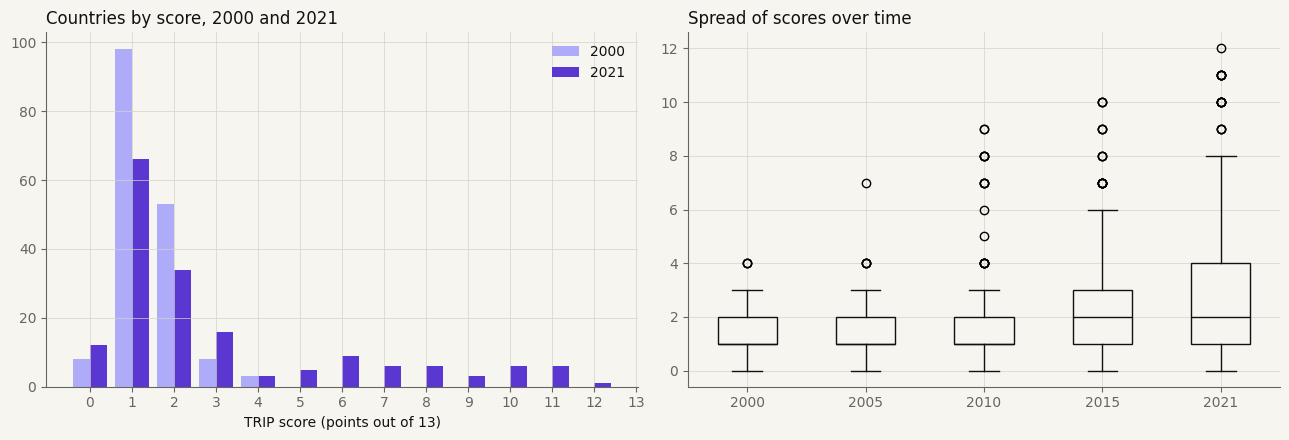

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for yr, color in [(2000, PRIMARY_LIGHT), (2021, PRIMARY)]:
    counts = scored[scored.year == yr].trip_score.value_counts().sort_index()
    axes[0].bar(counts.index + (-0.2 if yr == 2000 else 0.2), counts.values, width=0.4, color=color, label=str(yr))
axes[0].set_xticks(range(14))
axes[0].set_xlabel("TRIP score (points out of 13)")
axes[0].set_title("Countries by score, 2000 and 2021", loc="left")
axes[0].legend(frameon=False)

box_years = [2000, 2005, 2010, 2015, 2021]
bp = axes[1].boxplot([scored[scored.year == y].trip_score for y in box_years], tick_labels=box_years, patch_artist=True)
for patch in bp["boxes"]:
    patch.set_facecolor(PAPER); patch.set_edgecolor(TEXT)
for key in ("whiskers", "caps", "medians"):
    for line in bp[key]:
        line.set_color(TEXT)
axes[1].set_title("Spread of scores over time", loc="left")
fig.tight_layout()

print("2021 score counts:", scored[scored.year == 2021].trip_score.value_counts().sort_index().astype(int).to_dict())

In 2000 no country scored above 4. In 2021 most countries are still packed at
1 or 2 points, and the rest spread out in a long, thin tail up to 12. It is not
two neat groups; it is one large group that stayed and a scattered minority
that left. Before-and-after histograms show this well but lose the timing,
which is why the article uses the percentile chart instead.

## 8. Regions

My first assumption was that region would explain little. I tested it.

Average score by region, points out of 13:


year,2000,2021
e_regionpol_6C,,
W. Europe and N. America,2.3,7.5
E. Europe and C. Asia,1.9,4.4
L. American and the Caribbean,1.2,3.3
Asia and Pacific,1.2,2.2
Sub-Saharan Africa,1.1,1.2
Middle East and N. Africa,1.1,0.9


Western Europe and North America hold 11 of the 13 highest scores in 2021


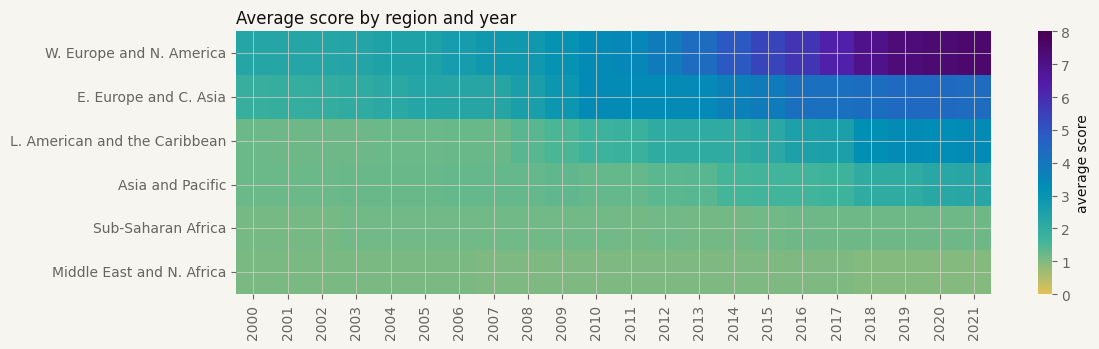

In [11]:
d21 = scored[scored.year == 2021].copy()
regions = (scored[scored.year.isin([2000, 2021])]
           .groupby(["e_regionpol_6C", "year"])["trip_score"].mean().unstack().round(1)
           .sort_values(2021, ascending=False))
print("Average score by region, points out of 13:")
display(regions)

heat = scored.groupby(["e_regionpol_6C", "year"])["trip_score"].mean().unstack().loc[regions.index]
fig, ax = plt.subplots(figsize=(12, 3.6))
sns.heatmap(heat, cmap=seq_cmap, vmin=0, vmax=8, cbar_kws={"label": "average score"}, ax=ax)
ax.set_title("Average score by region and year", loc="left"); ax.set_xlabel(""); ax.set_ylabel("")
fig.tight_layout()

top13 = d21.nlargest(13, "trip_score")
print(f"Western Europe and North America hold {top13.e_regionpol_6C.str.startswith('W.').sum()} of the 13 highest scores in 2021")

In [12]:
g = d21.groupby("e_regionpol_6C")["trip_score"]
d21["vs_region"] = (d21.trip_score - g.transform("mean")) / g.transform("std")
cols = ["country_name", "e_regionpol_6C", "trip_score", "vs_region"]
print("Furthest above and below their own region's average (in standard deviations), 2021:")
pd.concat([d21.nlargest(8, "vs_region")[cols], d21.nsmallest(8, "vs_region")[cols]]).round(2)

Furthest above and below their own region's average (in standard deviations), 2021:


,country_name,e_regionpol_6C,trip_score,vs_region
551,Pakistan,Asia and Pacific,11.0,3.72
3414,Israel,Middle East and N. Africa,4.0,3.15
137,South Africa,Sub-Saharan Africa,3.0,3.02
2172,Uruguay,L. American and the Caribbean,12.0,2.98
746,India,Asia and Pacific,8.0,2.45
459,Bolivia,L. American and the Caribbean,9.0,1.95
3138,Croatia,E. Europe and C. Asia,9.0,1.73
1137,Mozambique,Sub-Saharan Africa,2.0,1.36
3184,Cyprus,W. Europe and N. America,1.0,-2.03
608,South Sudan,Sub-Saharan Africa,0.0,-1.97


I was wrong about region. Western Europe clearly leads, with an average of 7.5
points against less than 1 in the Middle East and North Africa, and it holds 11
of the 13 highest scores.

What region does not explain are the exceptions. Pakistan, Israel, South
Africa, Uruguay and India sit far above their regions; Cyprus, Austria, Italy
and Switzerland sit well below Western Europe's average. Argentina, which I
had pencilled in as an outlier, is not one: Uruguay and Bolivia score higher in
the same region.

That changed the map section of the article. Instead of claiming that geography
doesn't matter, it shows where the top is and then zooms in on the exceptions.

## 9. The thirteen indicators

Which rights moved, and which didn't?

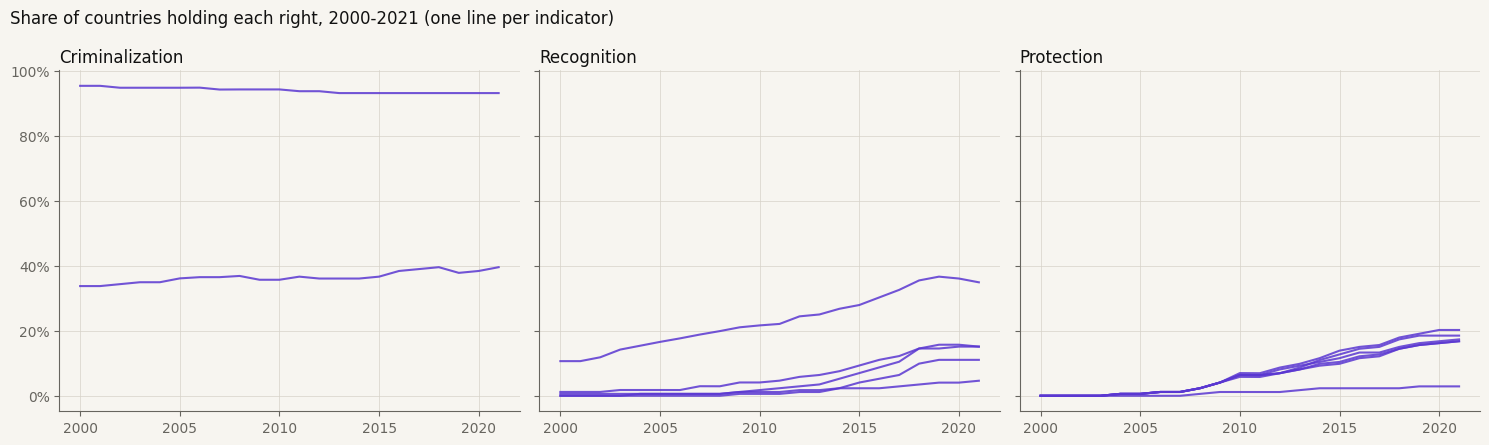

In [13]:
rows = []
for col, held, label, group in INDICATORS:
    share = data.groupby("year")[col].apply(lambda s: (s.dropna() == held).mean())
    rows += [{"year": y, "col": col, "label": label, "group": group, "share": v} for y, v in share.items()]
adoption = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, group in zip(axes, ["Criminalization", "Recognition", "Protection"]):
    for col, line in adoption[adoption.group == group].groupby("col"):
        ax.plot(line.year, line.share, color=PRIMARY, lw=1.5, alpha=0.85)
    ax.set_title(group, loc="left")
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
fig.suptitle("Share of countries holding each right, 2000-2021 (one line per indicator)", x=0.01, ha="left")
fig.tight_layout()

year,group,share_2000,share_2021,change
label,,,,
No direct criminalization,Criminalization,95.3%,93.1%,-2.2%
No indirect criminalization,Criminalization,33.7%,39.5%,+5.8%
Legal gender marker change,Recognition,10.7%,34.9%,+24.2%
No divorce requirement,Recognition,1.2%,15.1%,+13.9%
No surgery or physical requirement,Recognition,0.0%,15.1%,+15.1%
No psychiatric diagnosis required,Recognition,0.6%,11.0%,+10.5%
Nonbinary or third gender marker,Recognition,0.0%,4.6%,+4.6%
Protection in employment,Protection,0.0%,20.2%,+20.2%
General anti-discrimination law,Protection,0.0%,18.5%,+18.5%


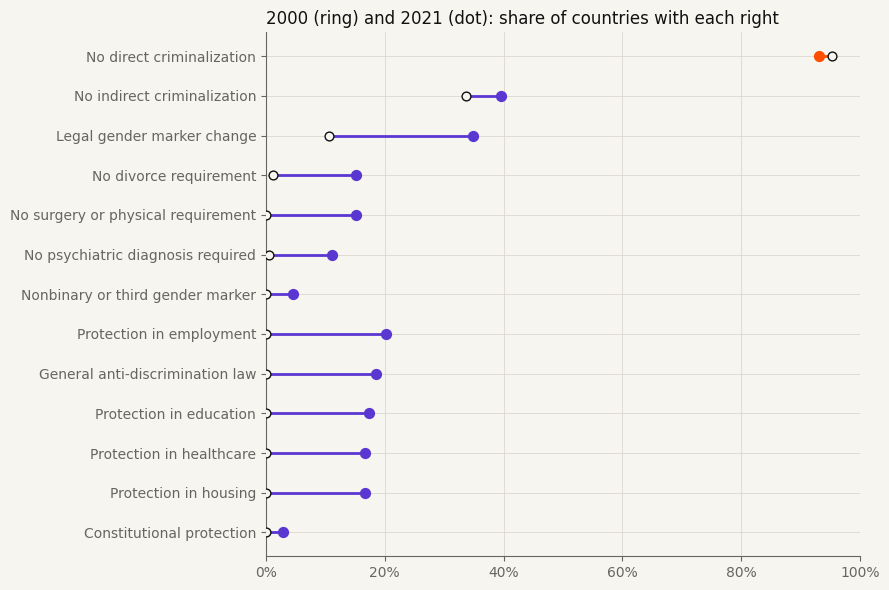

In [14]:
snap = (adoption[adoption.year.isin([2000, 2021])]
        .pivot_table(index=["group", "label"], columns="year", values="share")
        .rename(columns={2000: "share_2000", 2021: "share_2021"}))
snap["change"] = snap.share_2021 - snap.share_2000
order = ["Criminalization", "Recognition", "Protection"]
snap = snap.reset_index().assign(g=lambda t: t.group.map(order.index)).sort_values(["g", "share_2021"], ascending=[True, False]).drop(columns="g")

fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(snap))[::-1]
for yi, (_, r) in zip(y, snap.iterrows()):
    color = PRIMARY if r.change >= 0 else ACCENT
    ax.plot([r.share_2000, r.share_2021], [yi, yi], color=color, lw=2)
    ax.scatter(r.share_2000, yi, s=40, facecolor=PAPER, edgecolor=TEXT, zorder=3)
    ax.scatter(r.share_2021, yi, s=50, color=color, zorder=3)
ax.set_yticks(y, snap.label)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_xlim(0, 1)
ax.set_title("2000 (ring) and 2021 (dot): share of countries with each right", loc="left")
fig.tight_layout()

snap.set_index("label")[["group", "share_2000", "share_2021", "change"]].style.format(
    {"share_2000": "{:.1%}", "share_2021": "{:.1%}", "change": "{:+.1%}"})

In [15]:
first_nb = scored[scored.nb3g == 1].groupby("country_name")["year"].min().sort_values()
print("First year with a nonbinary or third gender marker:", first_nb.to_dict())

First year with a nonbinary or third gender marker: {'Pakistan': 2009, 'Nepal': 2012, 'Bangladesh': 2014, 'India': 2014, 'Malta': 2017, 'Uruguay': 2018, 'Iceland': 2019, 'Argentina': 2021}


Recognition moved first and fastest: legal gender change went from 11% of
countries to 35%. The conditions around it loosened more slowly. Protection
started from zero in every category and reached about 17-20%, except
constitutional protection, which only five countries have. Eight countries
offer a nonbinary or third gender marker, half of them in South Asia.

Direct criminalization is the only indicator that got worse.

The small multiples show all of this, but thirteen overlapping lines are hard
to read. The dot plot compresses each indicator to its start and end, and that
became the third chart of the article.

## 10. Going backwards

The indicator view says only one right declined overall. I wanted to know
whether individual countries lost ground at any point, not just between the
first and last year.

In [16]:
s = scored.sort_values(["country_text_id", "year"]).copy()
s["previous"] = s.groupby("country_text_id")["trip_score"].shift()
drops = s[s.trip_score < s.previous].copy()

def lost(row):
    before = s[(s.country_text_id == row.country_text_id) & (s.year == row.year - 1)].iloc[0]
    return ", ".join(LABEL[c] for c in HELD if before[c] == HELD[c] and row[c] != HELD[c])

drops["lost"] = drops.apply(lost, axis=1)
print(f"{len(drops)} drops from one year to the next, in {drops.country_text_id.nunique()} countries")
print("\nWhich right was lost:")
print(drops["lost"].str.split(", ").explode().value_counts().to_string())
drops[["country_name", "year", "previous", "trip_score", "lost"]].reset_index(drop=True)

30 drops from one year to the next, in 21 countries

Which right was lost:
lost
No indirect criminalization           23
No direct criminalization              4
Legal gender marker change             3
No surgery or physical requirement     1


,country_name,year,previous,trip_score,lost
0,Bulgaria,2021,3.0,2.0,Legal gender marker change
1,Brazil,2003,2.0,1.0,No indirect criminalization
2,Brazil,2013,2.0,1.0,No indirect criminalization
3,Ecuador,2014,3.0,2.0,No indirect criminalization
4,The Gambia,2013,1.0,0.0,No direct criminalization
5,Equatorial Guinea,2014,2.0,1.0,No indirect criminalization
6,Equatorial Guinea,2021,2.0,1.0,No indirect criminalization
7,Greece,2012,3.0,2.0,No indirect criminalization
8,Honduras,2001,2.0,1.0,No indirect criminalization
9,Haiti,2009,2.0,1.0,No indirect criminalization


In [17]:
crim = lambda y: set(scored[(scored.year == y) & (scored.dir_crim == 1)].country_text_id)
print("Direct criminalization in 2021 but not in 2000:", sorted(names[list(crim(2021) - crim(2000))]))
print("In 2000 but not in 2021:", sorted(names[list(crim(2000) - crim(2021))]))
print("Lower in 2021 than in 2000:", sorted(change[change.change < 0].country))

Direct criminalization in 2021 but not in 2000: ['Indonesia', 'Kuwait', 'Oman', 'South Sudan', 'The Gambia']
In 2000 but not in 2021: ['Guyana']
Lower in 2021 than in 2000: ['Cambodia', 'Equatorial Guinea', 'Indonesia', 'Kuwait', 'Oman', 'The Gambia']


Twenty-one countries lost at least one protection at some point. Six ended the
period lower than they started.

The clearest cases are new criminal laws (Indonesia, Kuwait, The Gambia, Oman,
and South Sudan from independence) and recognition being taken away (Hungary in
2020, Bulgaria and Kyrgyzstan in 2021).

Most of the other drops come from indirect criminalization, which switches on
and off in countries like Brazil, Haiti, Kyrgyzstan and Panama. That indicator
covers laws not written about trans people but used against them, so its
year-to-year changes are harder to interpret. In the article I mention it, but
I don't build any claim on it alone.

## 11. Recognition versus protection, and choosing the country cards

Section 9 showed recognition and protection moving at different speeds across
the world. I wanted to see whether individual countries split them too, because
that would be a better way to introduce specific countries than a ranking.

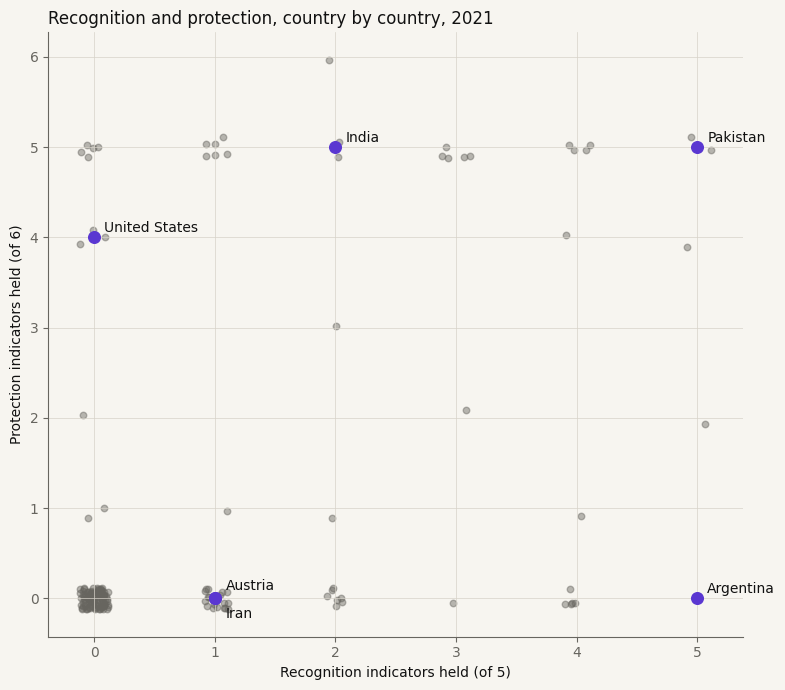

In [18]:
REC = ["gmc", "gmcphys", "gmcpsych", "gmcdiv", "nb3g"]
PRO = ["adp_general", "adp_employment", "adp_education", "adp_healthcare", "adp_housing", "adp_constitution"]
lgb_2020 = data[data.year == 2020].set_index("country_text_id")["lgb_percent"]

d21["recognition"] = sum(holds(d21, c).astype(int) for c in REC)
d21["protection"] = sum(holds(d21, c).astype(int) for c in PRO)
d21["lgb_2020"] = d21.country_text_id.map(lgb_2020)

fig, ax = plt.subplots(figsize=(8, 7))
jitter = np.random.default_rng(1).uniform(-0.12, 0.12, (2, len(d21)))
ax.scatter(d21.recognition + jitter[0], d21.protection + jitter[1], s=22, color=GREY, alpha=0.45)
offsets = {"AUT": (8, 6), "IRN": (8, -14)}   # Austria and Iran share a spot
for iso in ["ARG", "IND", "AUT", "PAK", "IRN", "USA"]:
    r = d21.set_index("country_text_id").loc[iso]
    ax.scatter(r.recognition, r.protection, s=70, color=PRIMARY, zorder=3)
    ax.annotate(r.country_name.replace(" of America", ""), (r.recognition, r.protection),
                xytext=offsets.get(iso, (7, 4)), textcoords="offset points")
ax.set_xlabel("Recognition indicators held (of 5)"); ax.set_ylabel("Protection indicators held (of 6)")
ax.set_title("Recognition and protection, country by country, 2021", loc="left")
fig.tight_layout()

They clearly split. Plenty of countries have full or near-full recognition and
no protection, and plenty have protection with very little recognition. I used
the scatter to sort countries into profiles, then looked at the candidates for
each one.

In [19]:
view = d21.set_index("country_name")
profiles = {
    "Recognition without protection (recognition 4+, protection 0)":
        view[(view.recognition >= 4) & (view.protection == 0)],
    "Protection, but recognition with conditions (protection 4+, recognition 2 or less)":
        view[(view.protection >= 4) & (view.recognition <= 2)],
    "Legal gender change only with every requirement (gender change, nothing else in recognition)":
        view[(view.gmc == 1) & (view.recognition == 1)],
    "Big gap between LGB and trans rights (LGB 2020 at least 50 points higher)":
        view[(view.lgb_2020 - view.trip_percent) >= 0.5],
    "Trans rights far ahead of LGB rights (TRIP at least 50 points higher)":
        view[(view.trip_percent - view.lgb_2020) >= 0.5],
}
for title, group in profiles.items():
    print(f"{title}:\n  {', '.join(group.index)}\n")

Recognition without protection (recognition 4+, protection 0):
  Colombia, Brazil, Argentina, Costa Rica, Ireland, Denmark

Protection, but recognition with conditions (protection 4+, recognition 2 or less):
  Albania, United States of America, Bolivia, India, Kosovo, Canada, Australia, Georgia, Bosnia and Herzegovina, Croatia, Czechia, North Macedonia, Montenegro, Serbia, Slovakia, Slovenia, Hungary

Legal gender change only with every requirement (gender change, nothing else in recognition):
  Switzerland, Japan, Vietnam, South Korea, Botswana, Iran, Italy, Latvia, Mongolia, Panama, Turkey, China, Kazakhstan, Namibia, Uzbekistan, Austria, Bosnia and Herzegovina, Cuba, Czechia, Estonia, Montenegro, Romania, Serbia, Slovakia, Slovenia

Big gap between LGB and trans rights (LGB 2020 at least 50 points higher):
  South Africa, Spain, Austria

Trans rights far ahead of LGB rights (TRIP at least 50 points higher):
  Pakistan, India



From each profile I picked one country, aiming for cases a reader might
recognise and that say something on their own:

- **Argentina** for recognition without protection. It is the best-known case:
  the first self-ID law in the world, in 2012.
- **India** for protection with conditions: four sector protections and a
  general law, but legal gender change still needs medical steps.
- **Austria** for the LGB-trans gap: 82% on LGB rights in 2020, 23% on TRIP.
  South Africa has the same gap, but Austria makes the point that wealth and a
  liberal reputation don't guarantee trans rights.
- **Pakistan** for the opposite gap: 85% on TRIP and 0% on LGB rights.
- **Iran** for legal gender change that only comes after surgery, a psychiatric
  diagnosis and divorce. It is the starkest example because same-sex relations
  are still punishable by death.
- **The United States** because readers will look for it, and because its
  score depends entirely on federal law: no national gender change, but
  federal protection in four sectors.

### A closer look at Argentina

An early draft of the cards called Argentina "the complete case" and gave it
100%. It does not hold up. I looked at its indicators year by year.

In [20]:
arg = scored[scored.country_text_id == "ARG"].set_index("year")
arg_view = arg[["trip_score"] + list(HELD)].loc[[2000, 2011, 2012, 2020, 2021]].astype(int)
arg_view.columns = ["score"] + [LABEL[c] for c in HELD]
display(arg_view.T)

print("Coded as indirectly criminalizing trans people in every year:", bool((arg.ind_crim == 1).all()))
jumps = s.assign(jump=s.trip_score - s.previous).nlargest(10, "jump")[["country_name", "year", "jump"]]
print(f"\nArgentina's 2012 jump: +{int(arg.trip_score[2012] - arg.trip_score[2011])}. The ten biggest one-year jumps:")
jumps.astype({"jump": int}).reset_index(drop=True)

year,2000,2011,2012,2020,2021
score,1,1,5,5,6
No direct criminalization,0,0,0,0,0
No indirect criminalization,1,1,1,1,1
Legal gender marker change,0,0,1,1,1
No surgery or physical requirement,2,2,0,0,0
No psychiatric diagnosis required,2,2,0,0,0
No divorce requirement,2,2,0,0,0
Nonbinary or third gender marker,0,0,0,0,1
General anti-discrimination law,0,0,0,0,0
Protection in employment,0,0,0,0,0


Coded as indirectly criminalizing trans people in every year: True

Argentina's 2012 jump: +4. The ten biggest one-year jumps:


,country_name,year,jump
0,Luxembourg,2018,9
1,Pakistan,2018,9
2,Uruguay,2018,6
3,Australia,2013,5
4,Belgium,2014,5
5,Bosnia and Herzegovina,2016,5
6,Bolivia,2010,5
7,Czechia,2009,5
8,Germany,2006,5
9,France,2012,5


Argentina's 6 out of 13 comes from three things:

- The 2012 law gave it all four recognition points at once (gender change, and
  no surgery, diagnosis or divorce requirement). The nonbinary marker added a
  fifth in 2021.
- TRIP codes Argentina as indirectly criminalizing trans people in every year
  from 2000 to 2021, so it never gets that point.
- It holds none of the six anti-discrimination protections. Its 2021 trans
  employment quota law is not an anti-discrimination law, so it doesn't count.

So the card now calls Argentina "recognition without protection", which is what
the data shows. Its 2012 jump (+4) is not one of the largest in the dataset
either. Pakistan and Luxembourg both jumped 9 points in 2018. The 2012 marker on
the article's heatmap is there because of what the law meant, not because of
the size of the change.

In [21]:
cards = []
for iso in ["ARG", "IND", "AUT", "PAK", "IRN", "USA"]:
    r = d21.set_index("country_text_id").loc[iso]
    history = scored[scored.country_text_id == iso]
    cards.append({
        "country": r.country_name,
        "score": f"{r.trip_score:.0f} of 13 ({r.trip_percent:.0%})",
        "recognition": f"{r.recognition}/5", "protection": f"{r.protection}/6",
        "LGB 2020": f"{r.lgb_2020:.0%}" if pd.notna(r.lgb_2020) else "",
        "gender change since": history.loc[history.gmc == 1, "year"].min(),
        "nonbinary marker since": history.loc[history.nb3g == 1, "year"].min(),
    })
pd.DataFrame(cards).set_index("country").astype({"gender change since": "Int64", "nonbinary marker since": "Int64"})

,score,recognition,protection,LGB 2020,gender change since,nonbinary marker since
country,,,,,,
Argentina,6 of 13 (46%),5/5,0/6,55%,2012,2021
India,8 of 13 (62%),2/5,5/6,9%,2014,2014
Austria,3 of 13 (23%),1/5,0/6,82%,2016,<NA>
Pakistan,11 of 13 (85%),5/5,5/6,0%,2018,2009
Iran,2 of 13 (15%),1/5,0/6,0%,2000,<NA>
United States of America,5 of 13 (38%),0/5,4/6,55%,<NA>,<NA>


This table is what the six cards in the article are written from.

## 12. Colonial law and the LGB comparison

Section 377 of the Indian Penal Code, drafted under British rule in 1860,
criminalized sexual acts "against the order of nature". It or similar clauses
spread across the empire, and several former colonies still have them. I
checked how those countries score today.

In [22]:
colonial = ["IND", "PAK", "BGD", "MYS", "SGP", "NGA", "KEN", "UGA"]
d21.set_index("country_text_id").loc[colonial, ["country_name", "dir_crim", "ind_crim", "trip_score"]].sort_values("trip_score")

,country_name,dir_crim,ind_crim,trip_score
country_text_id,,,,
MYS,Malaysia,1.0,1.0,0.0
NGA,Nigeria,1.0,1.0,0.0
SGP,Singapore,0.0,1.0,1.0
KEN,Kenya,0.0,1.0,1.0
UGA,Uganda,0.0,1.0,1.0
BGD,Bangladesh,0.0,1.0,3.0
IND,India,0.0,1.0,8.0
PAK,Pakistan,0.0,1.0,11.0


36% of countries differ by 10 points or more between the two scores


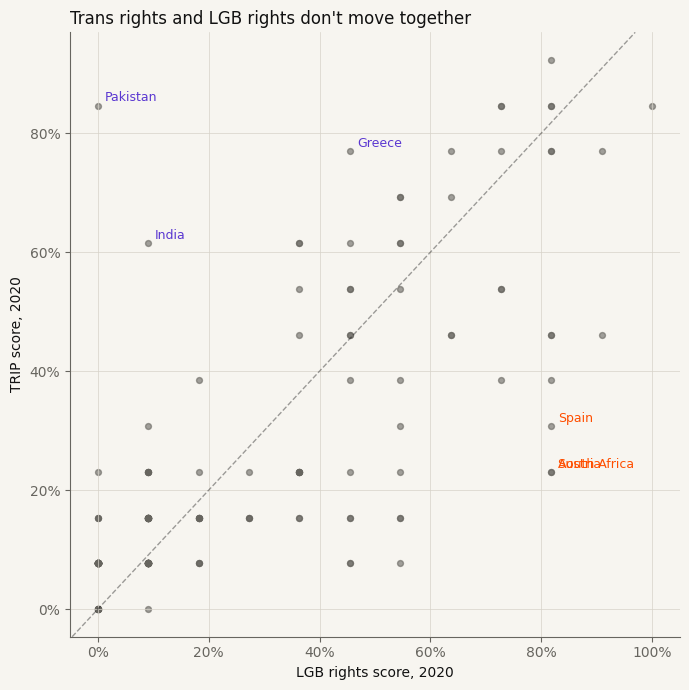

In [23]:
d20 = data[data.year == 2020].dropna(subset=["trip_percent", "lgb_percent"]).copy()
d20["gap"] = d20.trip_percent - d20.lgb_percent

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(d20.lgb_percent, d20.trip_percent, s=18, color=GREY, alpha=0.6)
ax.axline((0, 0), slope=1, color=TEXT, lw=1, ls="--", alpha=0.4)
for _, r in pd.concat([d20.nlargest(3, "gap"), d20.nsmallest(3, "gap")]).iterrows():
    ax.annotate(r.country_name, (r.lgb_percent, r.trip_percent), xytext=(5, 3), textcoords="offset points",
                color=PRIMARY if r.gap > 0 else ACCENT, fontsize=9)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0)); ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_xlabel("LGB rights score, 2020"); ax.set_ylabel("TRIP score, 2020")
ax.set_title("Trans rights and LGB rights don't move together", loc="left")
fig.tight_layout()
print(f"{(d20.gap.abs() >= 0.10).mean():.0%} of countries differ by 10 points or more between the two scores")

The colonial countries mostly sit at the bottom, though India and Pakistan are
exceptions with high scores. Only eight rows, so this became text and an aside
note in the article rather than a chart.

The LGB comparison is striking (Pakistan and Bangladesh at 0% on LGB rights,
Austria and South Africa at 82%), but it only exists for 2020 and it is a
different story. It survives as one aside note and in the country cards.

## 13. Every country, every year

Everything so far points at one image: all countries and all years at once,
sorted so the divergence is visible. My first version used a smooth colour
ramp, and most of the image came out in two or three similar shades. The
distribution of scores explains why.

Country-years scoring 0, 1 or 2: 78%
Highest score in any year: 12


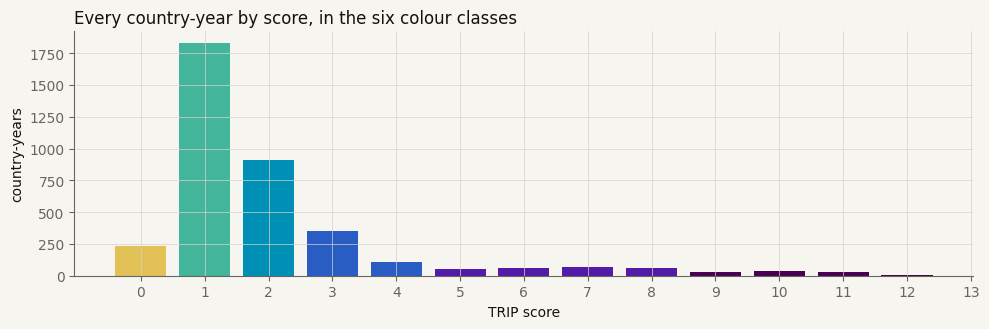

In [24]:
counts = scored.trip_score.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(counts.index, counts.values, color=[class_cmap(class_norm(v)) for v in counts.index], width=0.8)
ax.set_xticks(range(14)); ax.set_xlabel("TRIP score"); ax.set_ylabel("country-years")
ax.set_title("Every country-year by score, in the six colour classes", loc="left")
fig.tight_layout()
print(f"Country-years scoring 0, 1 or 2: {(scored.trip_score <= 2).mean():.0%}")
print(f"Highest score in any year: {scored.trip_score.max():.0f}")

78% of all country-years score 0, 1 or 2. An even colour scale would spend most
of its colours on scores that hardly occur. So I made the classes uneven: one
colour each for 0, 1 and 2, then 3-4, 5-8 and 9-13. The colours get darker at
every step (so the order still reads in greyscale) and shift hue as well (yellow,
teal, cyan, blue, violet, aubergine), so neighbouring rows stay distinguishable
even when they are a few pixels tall. I checked the palette for colour-blind
readers before using it.

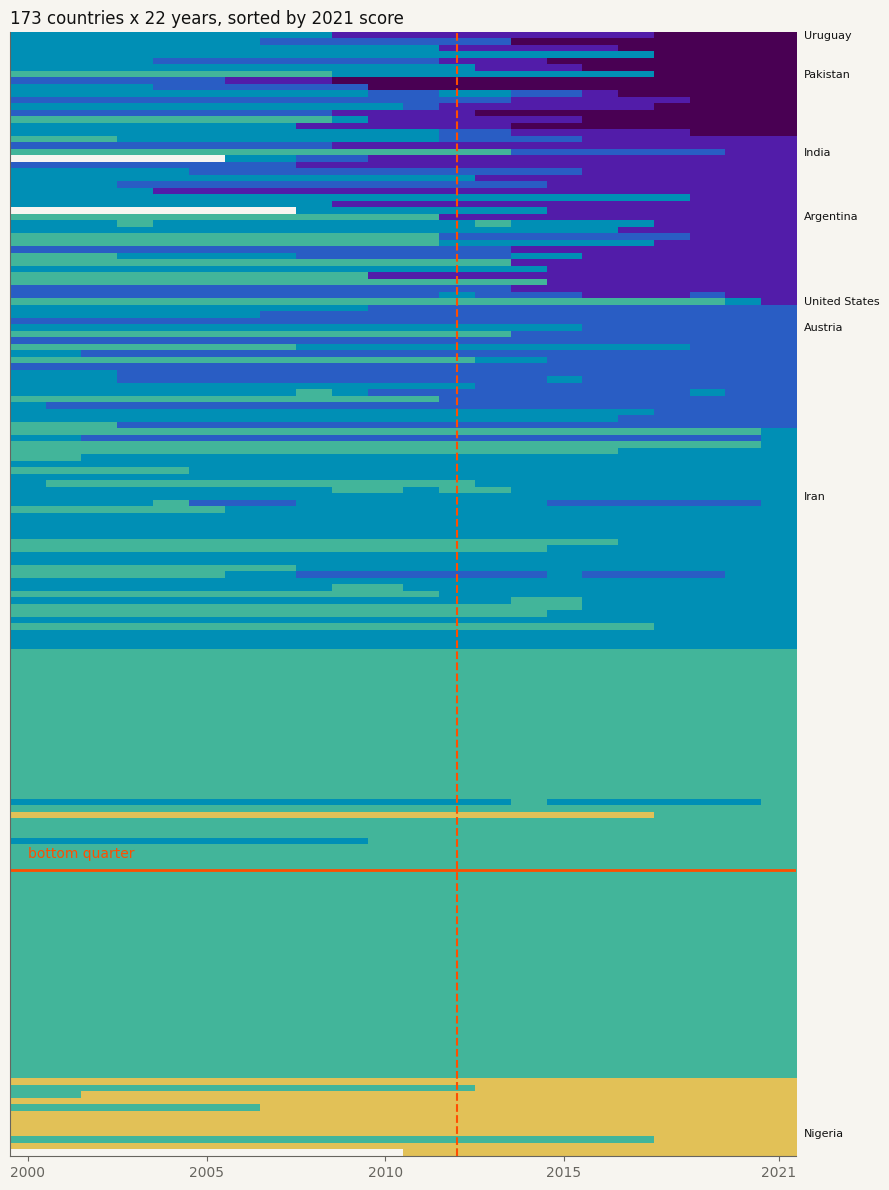

In [25]:
matrix = scores.loc[scores[2021].sort_values(ascending=False, kind="stable").index]
quarter = len(matrix) - int(np.ceil(len(matrix) / 4))

fig, ax = plt.subplots(figsize=(9, 12))
ax.imshow(matrix.values, aspect="auto", cmap=class_cmap, norm=class_norm, interpolation="none",
          extent=[matrix.columns.min() - 0.5, matrix.columns.max() + 0.5, len(matrix), 0])
ax.grid(False); ax.set_yticks([]); ax.set_xticks([2000, 2005, 2010, 2015, 2021])
ax.axhline(quarter, color=ACCENT, lw=2)
ax.axvline(2012, color=ACCENT, lw=1.5, ls="--")
ax.text(2000, quarter - 1.5, "bottom quarter", color=ACCENT, va="bottom")
for iso in ["URY", "PAK", "IND", "ARG", "USA", "AUT", "IRN", "NGA"]:
    ax.text(2021.7, matrix.index.get_loc(iso) + 0.5, names[iso].replace(" of America", ""), va="center", fontsize=8)
ax.set_title("173 countries x 22 years, sorted by 2021 score", loc="left")
fig.tight_layout()

2000: 89% of countries held 1 or 2 protections; none held more than 4
Countries reaching 5+ protections before 2012: 12; from 2012 to 2021: 30
2021: 42 countries hold 5+, 16 hold 9+
Bottom quarter in 2021: 44 countries, 39 with exactly their 2000 score


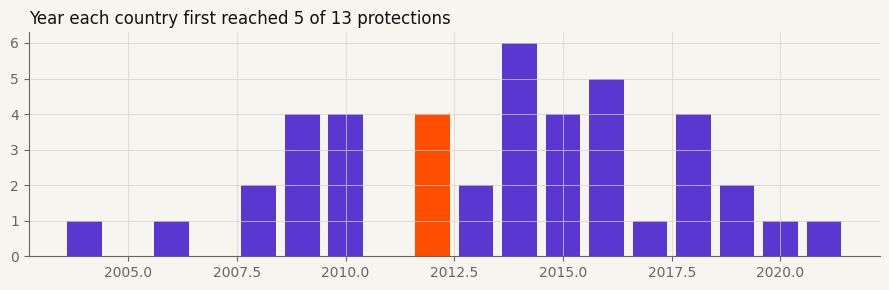

In [26]:
y2000 = scored[scored.year == 2000]
first5 = scores.ge(5).idxmax(axis=1)[scores.ge(5).any(axis=1)]
bottom = matrix.index[quarter:]
unchanged = (matrix.loc[bottom, 2021] == matrix.loc[bottom, 2000]).sum()
print(f"2000: {y2000.trip_score.isin([1, 2]).mean():.0%} of countries held 1 or 2 protections; none held more than {y2000.trip_score.max():.0f}")
print(f"Countries reaching 5+ protections before 2012: {(first5 < 2012).sum()}; from 2012 to 2021: {(first5 >= 2012).sum()}")
print(f"2021: {(scores[2021] >= 5).sum()} countries hold 5+, {(scores[2021] >= 9).sum()} hold 9+")
print(f"Bottom quarter in 2021: {len(bottom)} countries, {unchanged} with exactly their 2000 score")

fig, ax = plt.subplots(figsize=(9, 3))
per_year = first5.value_counts().sort_index()
ax.bar(per_year.index, per_year.values, color=[ACCENT if y == 2012 else PRIMARY for y in per_year.index])
ax.set_title("Year each country first reached 5 of 13 protections", loc="left")
fig.tight_layout()

These numbers are the steps of the heatmap in the article: an almost uniform
2000, a handful of countries moving before 2012, thirty more crossing five
protections afterwards, and a bottom quarter where 39 of 44 countries end
exactly where they started.

### Putting a number on the groups

The heatmap is convincing but visual. As a check, I clustered countries by
their 2000 and 2021 scores.

,countries,mean_2000,mean_2021
group,,,
High by 2021,16,2.12,10.31
Rising,24,1.83,6.42
Some movement,53,1.72,2.42
Stayed at the bottom,77,0.92,0.86


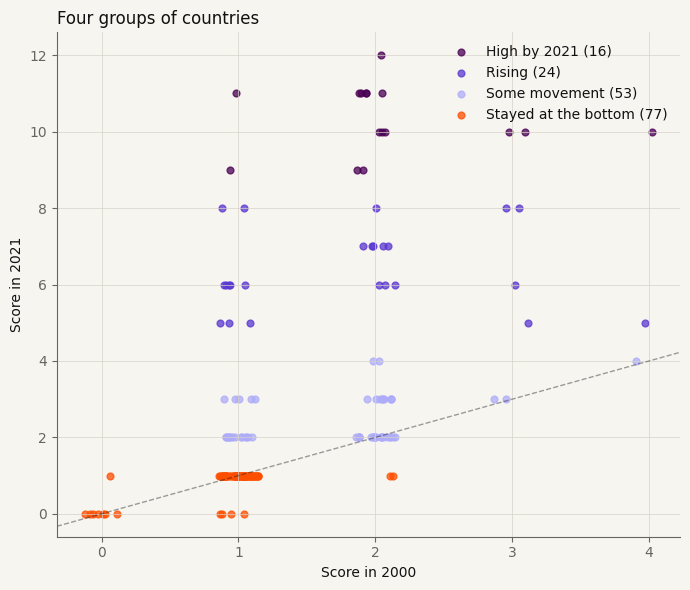

In [27]:
traj = change.copy()
km = KMeans(n_clusters=4, random_state=42, n_init=10).fit(traj[["score_2000", "score_2021"]])
traj["cluster"] = km.labels_
centres = pd.DataFrame(km.cluster_centers_, columns=["score_2000", "score_2021"])

def name(c):
    if c.score_2021 >= 8: return "High by 2021"
    if c.score_2021 - c.score_2000 >= 3: return "Rising"
    if c.score_2021 <= 2: return "Stayed at the bottom"
    return "Some movement"

traj["group"] = traj.cluster.map(centres.apply(name, axis=1))
summary = traj.groupby("group").agg(countries=("country", "count"), mean_2000=("score_2000", "mean"), mean_2021=("score_2021", "mean")).round(2)
display(summary.sort_values("mean_2021", ascending=False))

fig, ax = plt.subplots(figsize=(7, 6))
colors = {"High by 2021": "#490053", "Rising": PRIMARY, "Some movement": PRIMARY_LIGHT, "Stayed at the bottom": ACCENT}
for g, grp in traj.groupby("group"):
    ax.scatter(grp.score_2000 + np.random.default_rng(2).uniform(-.15, .15, len(grp)), grp.score_2021, s=24, alpha=0.75, color=colors[g], label=f"{g} ({len(grp)})")
ax.axline((0, 0), slope=1, color=TEXT, lw=1, ls="--", alpha=0.4)
ax.set_xlabel("Score in 2000"); ax.set_ylabel("Score in 2021"); ax.legend(frameon=False)
ax.set_title("Four groups of countries", loc="left")
fig.tight_layout()

The largest group is the one that stayed at the bottom, with an average that
barely changes between 2000 and 2021. It holds close to half the countries. The
rise in the average comes from the two smaller groups. This confirmed the
heatmap as the closing chart; the scatter itself didn't add anything the
heatmap doesn't already show, and the heatmap also shows when things changed.

## 14. Choosing the map's zoom stops

The map in the article zooms into four regions as the reader scrolls. Each stop
needed countries that either set an extreme or contradict what a reader would
expect of that region.

In [28]:
ssa = d21[d21.e_regionpol_6C == "Sub-Saharan Africa"]
print(f"Countries with 2 or fewer protections in 2021: {(d21.trip_score <= 2).mean():.0%}")
print(f"Sub-Saharan Africa scoring 0 or 1: {(ssa.trip_score <= 1).mean():.0%}; highest in the region: {ssa.trip_score.max():.0f}")
print("Constitutional protection:", d21[d21.adp_constitution == 1].country_name.tolist())
print("Nonbinary or third gender marker:", d21[d21.nb3g == 1].country_name.tolist())

stops = {"South America": ["URY", "ARG", "BRA"], "South Asia": ["PAK", "IND", "NPL", "BGD"],
         "Europe": ["MLT", "BEL", "AUT", "HUN"], "Africa": ["NGA", "UGA", "KEN", "ZAF"]}
table = d21.set_index("country_text_id")
pd.concat({stop: table.loc[isos, ["country_name", "trip_score", "dir_crim", "gmc", "nb3g", "adp_constitution"]]
           for stop, isos in stops.items()})

Countries with 2 or fewer protections in 2021: 65%
Sub-Saharan Africa scoring 0 or 1: 76%; highest in the region: 3
Constitutional protection: ['Bolivia', 'Ecuador', 'Cuba', 'Fiji', 'Malta']
Nonbinary or third gender marker: ['Bangladesh', 'Pakistan', 'Argentina', 'India', 'Nepal', 'Uruguay', 'Iceland', 'Malta']


country_name  trip_score  dir_crim  gmc  nb3g  adp_constitution
              country_text_id                                                                 
South America URY                   Uruguay        12.0       0.0  1.0   1.0               0.0
              ARG                 Argentina         6.0       0.0  1.0   1.0               0.0
              BRA                    Brazil         6.0       0.0  1.0   0.0               0.0
South Asia    PAK                  Pakistan        11.0       0.0  1.0   1.0               0.0
              IND                     India         8.0       0.0  1.0   1.0               0.0
              NPL                     Nepal         3.0       0.0  1.0   1.0               0.0
              BGD                Bangladesh         3.0       0.0  1.0   1.0               0.0
Europe        MLT                     Malta        11.0       0.0  1.0   1.0               1.0
              BEL                   Belgium        11.0       0.0  1.0   0.0               0.0
              AUT                   Austria         3.0       0.0  1.0   0.0               0.0
              HUN                   Hungary         7.0       0.0  0.0   0.0               0.0
Africa        NGA                   Nigeria         0.0       1.0  0.0   0.0               0.0
              UGA                    Uganda         1.0       0.0  0.0   0.0               0.0
              KEN                     Kenya         1.0       0.0  0.0   0.0               0.0
              ZAF              South Africa         3.0       0.0  1.0   0.0               0.0

- **South America:** Uruguay has the highest score anywhere; Argentina shows the
  gap between a famous law and a middling score; Brazil is a large country in
  the middle.
- **South Asia:** Pakistan outscores most of Europe; India is high but with
  medical conditions; Nepal and Bangladesh recognize a third gender at low
  overall scores.
- **Europe:** Malta is the only European country with constitutional
  protection; Austria is the LGB-trans gap; Hungary took recognition away in
  2020; Belgium stands in for the group at the top.
- **Africa:** Nigeria criminalizes directly; South Africa is the regional high
  point. Kenya and Uganda are there for the colonial-law context, which TRIP
  itself does not measure.

## 15. From notebook to article

The article has four charts, each answering one question:

| Article section | Chart | Built from |
|---|---|---|
| What the world's laws say about trans people | Distribution over time (average, median, middle half, 90th and 25th percentile) | Sections 3, 6 |
| A map of exceptions | Zoomable world map, 2021, in the six score classes | Sections 8, 14 |
| Recognition first, protection later | Dot plot of the 13 indicators, 2000 and 2021, plus "Going backwards" and the country cards | Sections 9, 10, 11 |
| Every country, every year | Heatmap of all countries and years, with country search | Sections 7, 13 |

What I tried and left out:

| Explored | Section | Why it didn't become a chart |
|---|---|---|
| Correlation matrix and ranking | 4 | Answers what predicts the score, not how it changed |
| Biggest movers | 5 | A ranking flattens the distribution |
| 10th percentile band | 6 | Identical to the 25th percentile every year |
| Histograms and boxplots | 7 | Show the shape but lose the timing |
| Regional averages | 8 | Hide the exceptions, which are the story |
| 13-line indicator time series | 9 | Too many overlapping lines; the dot plot reads faster |
| Indirect criminalization drops | 10 | Too unstable to carry a claim alone |
| Recognition vs protection scatter | 11 | Used to choose the country cards instead |
| Colonial law table | 12 | Eight rows; works better as text |
| LGB vs trans scatter | 12 | One year only, and a different story |
| Smooth colour ramp | 13 | Most of the heatmap fell into two or three shades |
| Cluster scatter | 13 | Confirms the heatmap without adding to it |

### Fact sheet

Every number in the article, recomputed from the cells above. When the text
changes, I check it against this table.

In [29]:
pct = lambda v: f"{v:.1%}"
facts = {
    "Countries with data, 2000 / 2021": f"{len(y2000)} / {len(d21)}",
    "Countries scoring exactly 1 in 2000 (no direct criminalization only)": int((y2000.trip_score == 1).sum()),
    "Countries criminalizing directly, 2000 / 2021": f"{(y2000.dir_crim == 1).sum()} / {(d21.dir_crim == 1).sum()}",
    "Average, 2000 / 2021": f"{pct(dist['mean'][2000])} / {pct(dist['mean'][2021])}",
    "Median, 2000 / 2021": f"{pct(dist['median'][2000])} / {pct(dist['median'][2021])}",
    "25th percentile, 2000 / 2021": f"{pct(dist.p25[2000])} / {pct(dist.p25[2021])}",
    "75th percentile, 2000 / 2021": f"{pct(dist.p75[2000])} / {pct(dist.p75[2021])}",
    "90th percentile, 2000 / 2021": f"{pct(dist.p90[2000])} / {pct(dist.p90[2021])}",
    "Interquartile range, 2000 / 2021 (points)": f"{(dist.p75 - dist.p25)[2000]*100:.1f} / {(dist.p75 - dist.p25)[2021]*100:.1f}",
    "Countries that never changed score": len(never),
    "Highest score in any year": f"{scored.trip_score.max():.0f} (Uruguay)",
    "Share with 2 or fewer protections, 2021": f"{(d21.trip_score <= 2).mean():.0%}",
    "Western Europe and N. America in the top 13, 2021": int(top13.e_regionpol_6C.str.startswith("W.").sum()),
    "Western Europe and N. America average, 2021 (points)": regions.loc["W. Europe and N. America", 2021],
    "Sub-Saharan Africa scoring 0 or 1": f"{(ssa.trip_score <= 1).mean():.0%}",
    "Countries with constitutional protection": int((d21.adp_constitution == 1).sum()),
    "Countries with a nonbinary or third gender marker": int((d21.nb3g == 1).sum()),
    "Countries that lost a protection at some point": drops.country_text_id.nunique(),
    "Countries lower in 2021 than in 2000": int((change.change < 0).sum()),
    "Share with 1 or 2 protections, 2000": f"{y2000.trip_score.isin([1, 2]).mean():.0%}",
    "Reached 5+ protections before 2012 / from 2012": f"{(first5 < 2012).sum()} / {(first5 >= 2012).sum()}",
    "Countries with 5+ / 9+ protections, 2021": f"{(scores[2021] >= 5).sum()} / {(scores[2021] >= 9).sum()}",
    "Bottom quarter unchanged since 2000": f"{unchanged} of {len(bottom)}",
}
display(pd.Series(facts, name="value").to_frame())
display(snap.set_index("label")[["share_2000", "share_2021"]].map(pct))

,value
"Countries with data, 2000 / 2021",170 / 173
Countries scoring exactly 1 in 2000 (no direct criminalization only),98
"Countries criminalizing directly, 2000 / 2021",8 / 12
"Average, 2000 / 2021",10.9% / 23.5%
"Median, 2000 / 2021",7.7% / 15.4%
"25th percentile, 2000 / 2021",7.7% / 7.7%
"75th percentile, 2000 / 2021",15.4% / 30.8%
"90th percentile, 2000 / 2021",15.4% / 61.5%
"Interquartile range, 2000 / 2021 (points)",7.7 / 23.1
Countries that never changed score,88


year,share_2000,share_2021
label,,
No direct criminalization,95.3%,93.1%
No indirect criminalization,33.7%,39.5%
Legal gender marker change,10.7%,34.9%
No divorce requirement,1.2%,15.1%
No surgery or physical requirement,0.0%,15.1%
No psychiatric diagnosis required,0.6%,11.0%
Nonbinary or third gender marker,0.0%,4.6%
Protection in employment,0.0%,20.2%
General anti-discrimination law,0.0%,18.5%
